# Exploratory_Data_Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# import dataset
date_cols = ['order_purchase_timestamp', 'order_approved_at',
             'order_delivered_carrier_date', 'order_delivered_customer_date',
             'order_estimated_delivery_date']

orders_cleaned      = pd.read_csv('../data/interim/olist_orders_cleaned.csv', parse_dates=date_cols)
order_items_cleaned = pd.read_csv('../data/interim/olist_order_items_cleaned.csv')
customers_cleaned   = pd.read_csv('../data/interim/olist_customers_cleaned.csv')
payments_cleaned    = pd.read_csv('../data/interim/olist_ payments_cleaned.csv')
products_cleaned    = pd.read_csv('../data/interim/olist_products_cleaned.csv')
translation_cleaned = pd.read_csv('../data/interim/olist_ translation_cleaned.csv')
geolocation_cleaned = pd.read_csv('../data/interim/olist_geolocation_cleaned.csv')
reviews_cleaned     = pd.read_csv('../data/interim/olist_ reviews_cleaned.csv')
sellers_cleaned     = pd.read_csv('../data/interim/olist_sellers_cleaned.csv')

## EDA-01 — Univariate Analysis

In [3]:
orders_cleaned.dtypes

order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
purchase_to_approved_hours              float64
approval_to_carrier_hours               float64
carrier_to_customer_hours               float64
purchase_to_customer_hours              float64
purchase_to_estimated_hours             float64
dtype: object

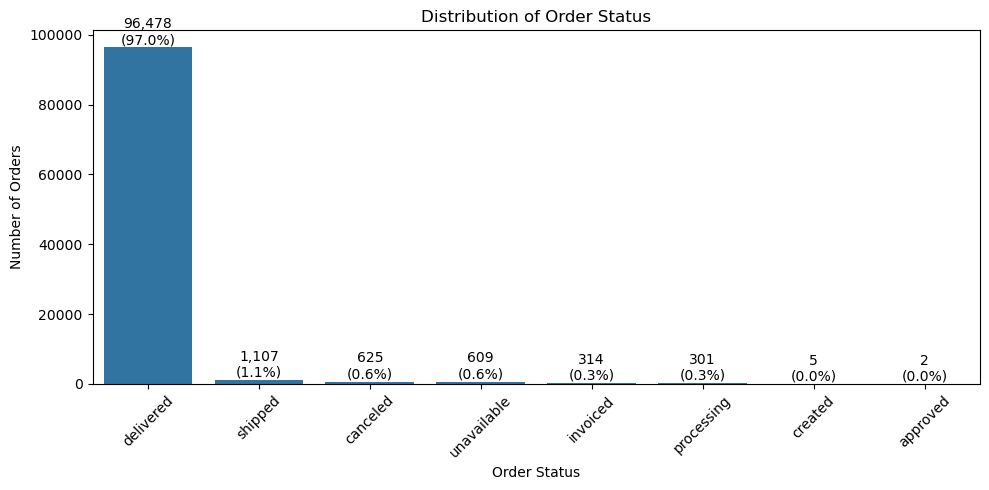

In [5]:
order_status_counts = orders_cleaned["order_status"].value_counts()
total_orders = order_status_counts.sum()

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=order_status_counts.index,
    y=order_status_counts.values
    
)

plt.title("Distribution of Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

# Add count and percentage labels
for bar in ax.patches:
    count = bar.get_height()
    percentage = (count / total_orders) * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count,
        f"{int(count):,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

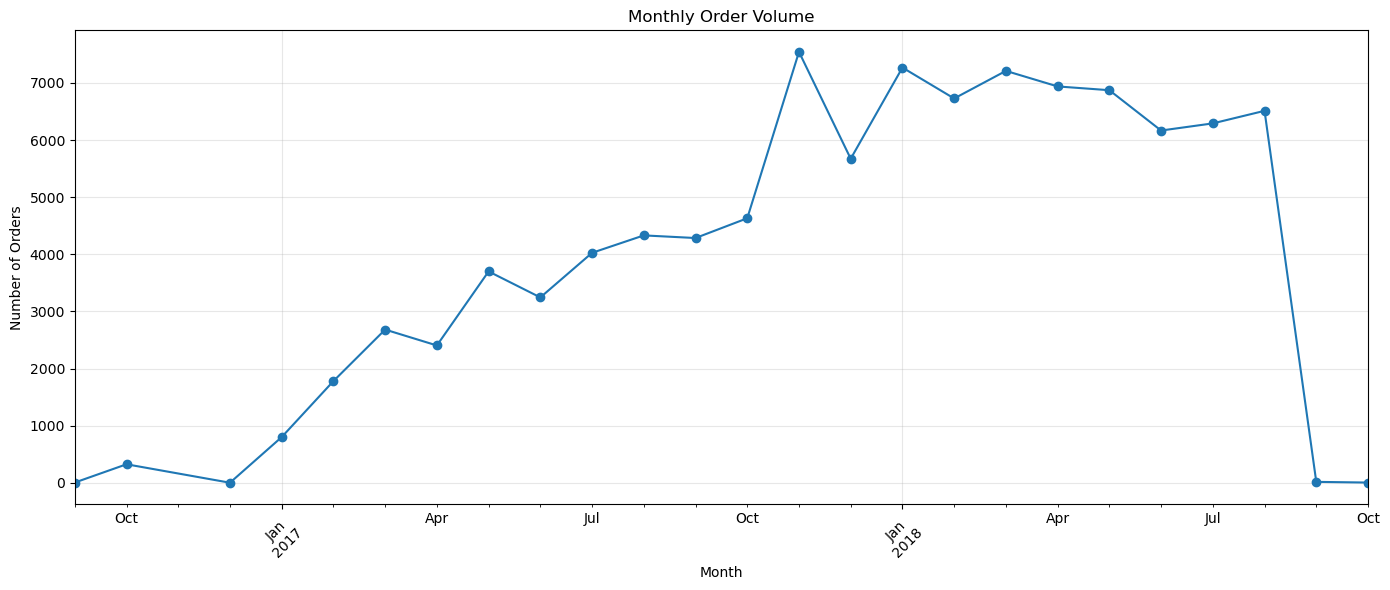

In [ ]:
monthly_orders = (
    orders_cleaned.groupby(orders_cleaned['order_purchase_timestamp'].dt.to_period("M")).size()
    )
monthly_orders

plt.figure(figsize=(14, 6))

monthly_orders.plot(kind="line", marker="o")

plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [67]:
orders_cleaned['has_invalid_duration'] = (
 (orders_cleaned['approval_to_carrier_hours'] < 0 ) |
 (orders_cleaned['carrier_to_customer_hours'] < 0)
)
orders_cleaned['has_invalid_duration'].sum()

np.int64(1382)

In [79]:
valid_orders = orders_cleaned[~orders_cleaned['has_invalid_duration']]
to_days = (valid_orders['purchase_to_customer_hours'] / 24)

to_days.agg(['min', 'mean', 'median','max'])

min         0.533414
mean       12.618974
median     10.271875
max       209.628611
Name: purchase_to_customer_hours, dtype: float64

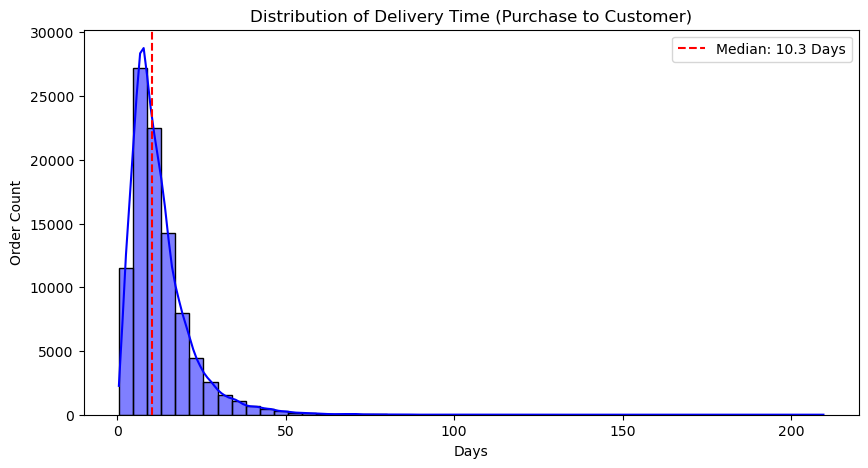

In [72]:
plt.figure(figsize=(10, 5))
sns.histplot(to_days, kde=True, bins=50, color='blue')
plt.title('Distribution of Delivery Time (Purchase to Customer)')
plt.xlabel('Days')
plt.ylabel('Order Count')
plt.axvline(to_days.median(), color='red', linestyle='--', label=f'Median: {to_days.median():.1f} Days')
plt.legend()
plt.show()

#### Delivery time distribution is right-skewed, with most orders concentrated at shorter delivery times and a smaller number of orders taking considerably longer.

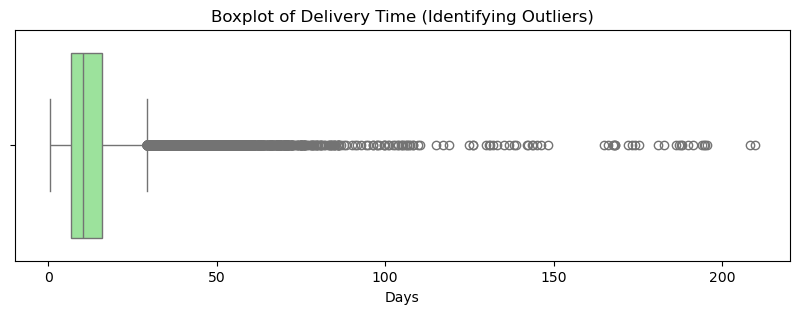

In [73]:
plt.figure(figsize=(10, 3))
sns.boxplot(x=to_days, color='lightgreen')
plt.title('Boxplot of Delivery Time (Identifying Outliers)')
plt.xlabel('Days')
plt.show()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_33392\3031259664.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=lifecycle_long, x='Stage', y='Days', palette='viridis', showfliers=False)


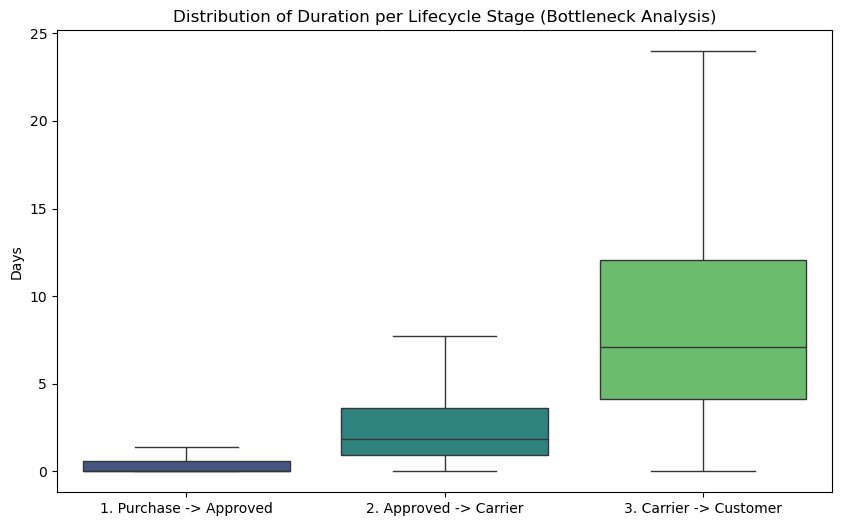

In [74]:
lifecycle_long = pd.DataFrame({
    '1. Purchase -> Approved': valid_orders['purchase_to_approved_hours'] / 24,
    '2. Approved -> Carrier': valid_orders['approval_to_carrier_hours'] / 24,
    '3. Carrier -> Customer': valid_orders['carrier_to_customer_hours'] / 24
}).melt(var_name='Stage', value_name='Days')

plt.figure(figsize=(10, 6))
sns.boxplot(data=lifecycle_long, x='Stage', y='Days', palette='viridis', showfliers=False)
plt.title('Distribution of Duration per Lifecycle Stage (Bottleneck Analysis)')
plt.ylabel('Days')
plt.xlabel('')
plt.show()

### The carrier-to-customer stage accounts for the largest portion of the order lifecycle based on median duration.

In [75]:
delivered_valid = orders_cleaned[
    (orders_cleaned['order_delivered_customer_date'].notna())
].copy()

delivered_valid['is_on_time'] = (
    delivered_valid['order_delivered_customer_date'] <= delivered_valid['order_estimated_delivery_date']
)

In [76]:
on_time_rate = delivered_valid['is_on_time'].mean() * 100
print(f"on time rate :  {on_time_rate:.2f}%")
print(f"total orders : {len(delivered_valid)}")

on time rate :  91.89%
total orders : 96476
